# 05 · Simulation study of local optima (plan, section 7)

Synthetic data with **K known routes** to flip the decision: route 0 is **near** the typical instance and the others
are **far**. Since the routes are known by construction, we can measure how many each method finds:

**route recall** = distinct routes found ÷ routes that exist,

using the **true** generative function (not the model) to decide whether a valid counterfactual uses route *k*.

**Hypothesis:** classical methods get stuck on the near route; QD finds all of them.

**Mitigating the risk raised by Mary** (data designed to favor the hypothesis):
1. generator and parameters fixed in `configs/simulation.yaml` with `frozen_on: 2026-11-20`, **before** running any
   method; the parameter hash goes to the data manifest and to every run manifest;
2. `simulation_shuffled`: same data, but the descriptor groups **do not** match the routes, removing the advantage
   MAP-Elites gets from a grid aligned with the routes by construction;
3. also report the cases where QD does **not** find every route (table at the end).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

In [2]:
import yaml
from cfqd import datasets as D, models as M
from cfqd.experiment import load_experiment, load_summaries, run_grid

cfg = yaml.safe_load((ROOT / "configs" / "simulation.yaml").read_text(encoding="utf-8"))
print("frozen on:", cfg["frozen_on"])
print(yaml.safe_dump(cfg["generator"], sort_keys=False))
df, meta = D.build("simulation")
print("parameter hash:", meta["generator_hash"], "| rows:", meta["n_rows"], "| favorable rate:", meta["favorable_rate"])
print("routes (feature indices):", meta["ground_truth"]["routes"])
print("thresholds:", meta["ground_truth"]["thresholds"])
print("share of favorable points per route (training data):", meta["favorable_share_by_route"])

frozen on: 2026-11-20
seed: 20261120
n_samples: 6000
n_routes: 4
features_per_route: 2
n_noise: 2
n_immutable: 1
near_distance: 1.0
far_distance: 3.0
label_noise: 0.1
base_fraction: 0.6
directions: up
descriptor: aligned



parameter hash: 82ede74c5d75 | rows: 6000 | favorable rate: 0.1872
routes (feature indices): [[0, 1], [2, 3], [4, 5], [6, 7]]
thresholds: [1.0, 3.0, 3.0, 3.0]
share of favorable points per route (training data): [0.59, 0.135, 0.148, 0.126]


In [3]:
rows = []
for n in ["simulation", "simulation_shuffled"]:
    ds = D.load_dataset(n, seed=0)
    for k in ["lr", "rf", "nn"]:
        rows.append(dict(dataset=n, model=k, acc_test=round(M.evaluate(M.get_model(ds, k), ds)["acc_test"], 3)))
pd.DataFrame(rows).pivot(index="dataset", columns="model", values="acc_test")

model,lr,nn,rf
dataset,,,
simulation,0.894,0.961,0.971
simulation_shuffled,0.894,0.961,0.971


Logistic regression cannot represent the "OR" between routes (its boundary is linear), so it learns only part of the
routes and the best achievable recall with LR is lower. That is a property of the explained model, not of the method.

## Run

`QUICK = True` runs a reduced version (1 seed, 5 instances) that fits in the notebook; for the paper run
`python scripts/run_batch.py --config configs/experiments/simulation.yaml`.

In [4]:
QUICK = True
exp = load_experiment(ROOT / "configs" / "experiments" / "simulation.yaml")
if QUICK:
    exp.update(seeds=[0], n_instances=5, out="results/simulation_quick")
_ = run_grid(exp, jobs=1)
s = load_summaries(exp)
print(len(s), "summary rows")

22 configurations, 0 already done, 22 to run, 2 skipped


[1/22] simulation__lr__map_elites__seed0: 36.48s


[2/22] simulation__lr__dice_genetic__seed0: 9.85s


[3/22] simulation__lr__wachter__seed0: 11.36s


[4/22] simulation__lr__face_knn__seed0: 3.96s


[5/22] simulation__rf__map_elites__seed0: 110.56s


... (14 outputs left out)

[20/22] simulation_shuffled__nn__dice_genetic__seed0: 6.97s


[21/22] simulation_shuffled__nn__wachter__seed0: 1.33s


[22/22] simulation_shuffled__nn__face_knn__seed0: 2.97s


330 summary rows


## Route recall per method

`near_route_found`: found the near route · `far_routes_found`: how many of the 3 far routes ·
`cf_on_no_true_route`: counterfactuals valid for the model but on no true route (model error).

In [5]:
aligned = s[s["dataset"] == "simulation"]
aligned.groupby(["model", "method", "budget"])[["success", "route_recall", "near_route_found", "far_routes_found",
                                               "cf_on_no_true_route", "n_valid"]].mean().round(2)

success  route_recall  near_route_found  far_routes_found  cf_on_no_true_route  n_valid
model method       budget                                                                                         
lr    dice_genetic 500         1.0          0.30               1.0               0.2                  4.6     10.0
                   2000        1.0          0.30               1.0               0.2                  4.6     10.0
                   10000       1.0          0.30               1.0               0.2                  4.6     10.0
      face_knn     500         1.0          0.20               0.6               0.2                  0.2      1.0
                   2000        1.0          0.20               0.6               0.2                  0.2      1.0
                   10000       1.0          0.20               0.6               0.2                  0.2      1.0
      map_elites   500         1.0          0.55               1.0               1.2                 16.2     60.2
                   2000        1.0          0.55               1.0               1.2                 27.0     88.0
                   10000       1.0          0.55               1.0               1.2                 35.0    113.0
      wachter      500         1.0          0.05               0.0               0.2                  0.8      1.0
                   2000        1.0          0.05               0.0               0.2                  0.8      1.0
                   10000       1.0          0.05               0.0               0.2                  0.8      1.0
nn    dice_genetic 500         1.0          0.40               0.8               0.8                  0.4     10.0
                   2000        1.0          0.40               0.8               0.8                  0.4     10.0
                   10000       1.0          0.40               0.8               0.8                  0.4     10.0
      face_knn     500         1.0          0.25               0.6               0.4                  0.0      1.0
                   2000        1.0          0.25               0.6               0.4                  0.0      1.0
                   10000       1.0          0.25               0.6               0.4                  0.0      1.0
      map_elites   500         1.0          0.90               1.0               2.6                 14.6     88.0
                   2000        1.0          0.90               1.0               2.6                 24.2    136.8
                   10000       1.0          0.90               1.0               2.6                 47.6    169.4
      wachter      500         1.0          0.05               0.2               0.0                  0.8      1.0
                   2000        1.0          0.05               0.2               0.0                  0.8      1.0
                   10000       1.0          0.05               0.2               0.0                  0.8      1.0
rf    dice_genetic 500         1.0          0.40               1.0               0.6                  0.8     10.0
                   2000        1.0          0.40               1.0               0.6                  0.8     10.0
                   10000       1.0          0.40               1.0               0.6                  0.8     10.0
      face_knn     500         1.0          0.25               0.8               0.2                  0.0      1.0
                   2000        1.0          0.25               0.8               0.2                  0.0      1.0
                   10000       1.0          0.25               0.8               0.2                  0.0      1.0
      map_elites   500         1.0          0.90               1.0               2.6                 45.6     90.0
                   2000        1.0          0.70               1.0               1.8                 79.6    140.2
                   10000       1.0          0.75               1.0               2.0                109.0    177.2

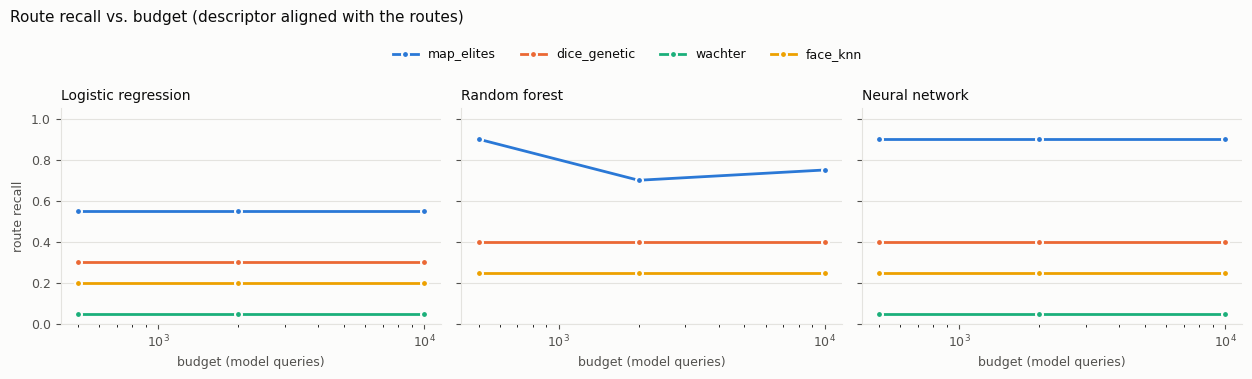

In [6]:
from cfqd.plots import budget_curves
fig = budget_curves(aligned, "route_recall", "Route recall vs. budget (descriptor aligned with the routes)",
                    "route recall", ylim=(0, 1.05))

## Robustness: shuffled descriptor

If MAP-Elites finds the routes only because its grid is aligned with them, its recall should drop on
`simulation_shuffled`. The other methods do not use the descriptor, so they should not change.

In [7]:
cmp = s.groupby(["dataset", "method", "budget"])["route_recall"].mean().unstack("dataset").round(2)
cmp["difference"] = (cmp["simulation_shuffled"] - cmp["simulation"]).round(2)
cmp

dataset              simulation  simulation_shuffled  difference
method       budget                                             
dice_genetic 500           0.37                 0.37        0.00
             2000          0.37                 0.37        0.00
             10000         0.37                 0.37        0.00
face_knn     500           0.23                 0.23        0.00
             2000          0.23                 0.23        0.00
             10000         0.23                 0.23        0.00
map_elites   500           0.78                 0.78        0.00
             2000          0.72                 0.72        0.00
             10000         0.73                 0.70       -0.03
wachter      500           0.05                 0.05        0.00
             2000          0.05                 0.05        0.00
             10000         0.05                 0.05        0.00

## Cases where QD does not find every route (to be reported in the paper)

In [8]:
me = s[s["method"] == "map_elites"]
misses = me[me["route_recall"] < 1].groupby(["dataset", "model", "budget"]).agg(
    instances=("instance_id", "nunique"), mean_recall=("route_recall", "mean")).reset_index()
print(f"{len(me[me['route_recall'] < 1])} of {len(me)} MAP-Elites runs without every route")
misses

56 of 90 MAP-Elites runs without every route


,dataset,model,budget,instances,mean_recall
0,simulation,lr,500,5,0.550000
1,simulation,lr,2000,4,0.437500
2,simulation,lr,10000,4,0.437500
3,simulation,nn,500,2,0.750000
4,simulation,nn,2000,2,0.750000
5,simulation,nn,10000,2,0.750000
6,simulation,rf,500,2,0.750000
7,simulation,rf,2000,4,0.625000
8,simulation,rf,10000,3,0.583333
9,simulation_shuffled,lr,500,4,0.500000
